# 实验五 条件性游览建议的抽取

从景区攻略和游记中提取适用条件与游览行动，记录实际地点和来源，并比较人群及条件类型的分布。

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
BASE=Path.cwd()
if not (BASE/"experiment.py").exists():
    raise RuntimeError("请在待提交目录启动Notebook")
if str(BASE) not in sys.path: sys.path.insert(0,str(BASE))
from corpus_io import load_corpus
from extract_rules import RULES, extract_candidates
from experiment import run
from evaluate_rules import evaluate

## 1 读取实验一正文与分句

以实验一结构化数据的 clean_content 为统一正文，保留其字符和段落，在原文上切分句段并记录位置。文章清洗与文档去重由实验一完成。

In [2]:
docs,sentences,summary=load_corpus(BASE/"data/clean_documents.json")
display(pd.DataFrame([{"输入文章":summary["input_records"],"独立文章":summary["records"],"句段":summary["sentences"]}]))
display(pd.DataFrame(summary["by_provenance"].items(),columns=["来源性质","文章数"]))
display(pd.DataFrame(sentences)[["sentence_id","doc_id","paragraph_index","text"]].head())

,输入文章,独立文章,句段
0,48,48,1406


,来源性质,文章数
0,dataset_corpus,15
1,editorial_route_guide,15
2,official_route_facts,3
3,synthetic_teaching,15


,sentence_id,doc_id,paragraph_index,text
0,GG_F01_S001,GG_F01,1,本篇记录可追溯的官方推荐路线事实，用于与游客实际路线比较。
1,GG_F01_S002,GG_F01,1,原发布页面通过上方参考链接查看，本文不冒充原网页完整文章。
2,GG_F01_S003,GG_F01,2,推荐行进顺序：午门-太和门-弘义阁(皇朝礼乐展)-太和殿-中和殿-保和殿-乾清门-乾清宫-交...
3,GG_F01_S004,GG_F01,3,这组顺序是推荐方案，不是游客的实际行走轨迹。
4,GG_F01_S005,GG_F01,3,来源没有明确给出的上午、中午、下午或逐点时刻，应保留为未知，不得为完成时间层级而补造官方时间。


## 2 条件识别与候选抽取

优先识别明确条件句，再处理人群、偏好和相邻上下文。必要条件、例外条件、否定与并列行动分别保留。

In [3]:
display(pd.DataFrame(RULES))
candidates=extract_candidates(sentences)
print("规则候选：",len(candidates))
display(pd.DataFrame(candidates)[["doc_id","rule_id","condition_text","advice_text","condition_operator"]].head(12))

规则候选： 90


,id,priority,pattern
0,R_IF_THEN,1,如果/假如/若/只要 + 条件 + 建议
1,R_ONLY_THEN,1,只有/仅当/仅在/唯有 + 条件 + 才/方才
2,R_UNLESS,1,除非 + 条件 + 否则
3,R_FOR,2,对于 + 适用情形 + 建议
4,R_VISITOR_PROFILE,3,陪同对象/偏好/时间 + 建议
5,R_COMPANION_CONTEXT,4,前句陪同对象 + 本句建议
6,R_LOCAL_SCENE,3,限定游览场景 + 建议
7,R_CAUSE_ADVICE,3,由于情形 + 建议
8,R_ACCESS_REQUIREMENT,3,进入场景 + 操作要求


,doc_id,rule_id,condition_text,advice_text,condition_operator
0,GG_O01,R_IF_THEN,想拍照或带孩子观察建筑细节,可以减少在入口附近停留的时间，把节奏留给中后段,any
1,GG_O01,R_IF_THEN,遇临时封闭或明显拥挤,应服从现场引导，必要时删减停留点，而不是把“两小时”当作必须完成的限时任务,any
2,GG_O02,R_IF_THEN,希望在较短时间内兼顾建筑与展陈,可以参考北京旅游网的两小时推荐路线二,all
3,GG_O02,R_IF_THEN,当天排队较多,可以压缩某一展厅的停留，而把整体方向保持下来,all
4,GG_O03,R_IF_THEN,同行者兴趣不同,可预先约定参观结束后的会合地点，避免有人留在展厅、有人已经继续向北,all
5,GG_O04,R_IF_THEN,遇等候,可以酌情缩短停留，避免在行程起点耗去大部分时间,all
6,GG_O04,R_VISITOR_PROFILE,带老人或孩子,可以在院落间适当休息,context
7,GG_O04,R_CAUSE_ADVICE,展陈较多,实际停留容易超过半天，建议按兴趣选出重点，其他部分以了解空间关系为主,context
8,GG_O04,R_IF_THEN,临近结束仍有未看完的内容,可以留待再次参观，不必在最后一段仓促穿行,all
9,GG_O05,R_IF_THEN,有临时闭馆、天气变化或体力下降,应及时减少支线，把休息和顺利离院纳入行程,any


## 3 人工复核与映射表

最终映射表已完成人工复核，条件边界、行动内容、分类与适用地点均结合原文核对。data/人工校验.json保存候选修正和补充关系，程序据此生成映射表。

,主体建议,其他地点,建议去重合并
0,95,10,0


,mapping_id,condition_text,advice_text,target_scope,provenance_kind
0,M001,只能选择一个博物馆可以去,那我一定选择故宫博物馆,故宫,dataset_corpus
1,M002,在皇家宫殿里遛娃,教育好熊孩子不要触碰到皇家文物,故宫,dataset_corpus
2,M003,里面很大很容易迷路,最好提前规划好游玩攻略,故宫,dataset_corpus
3,M004,带着老人,不能现去找住宿的地方,北京通用,dataset_corpus
4,M005,有计划出行日程,就把住宿都预定好,北京通用,dataset_corpus
5,M006,去哪儿上预订房间,建议朋友们慎选,北京通用,dataset_corpus
6,M007,当天气温14度，阴天，如果不刮风,穿两件棉T加件风衣刚好,天坛,dataset_corpus
7,M008,按顺序浏览,应该从南门进入,天坛,dataset_corpus
8,M009,时间充足的话,在里边散步拍照,天坛,dataset_corpus
9,M010,逛完天坛,出来直接吃晚饭刚好,天坛,dataset_corpus


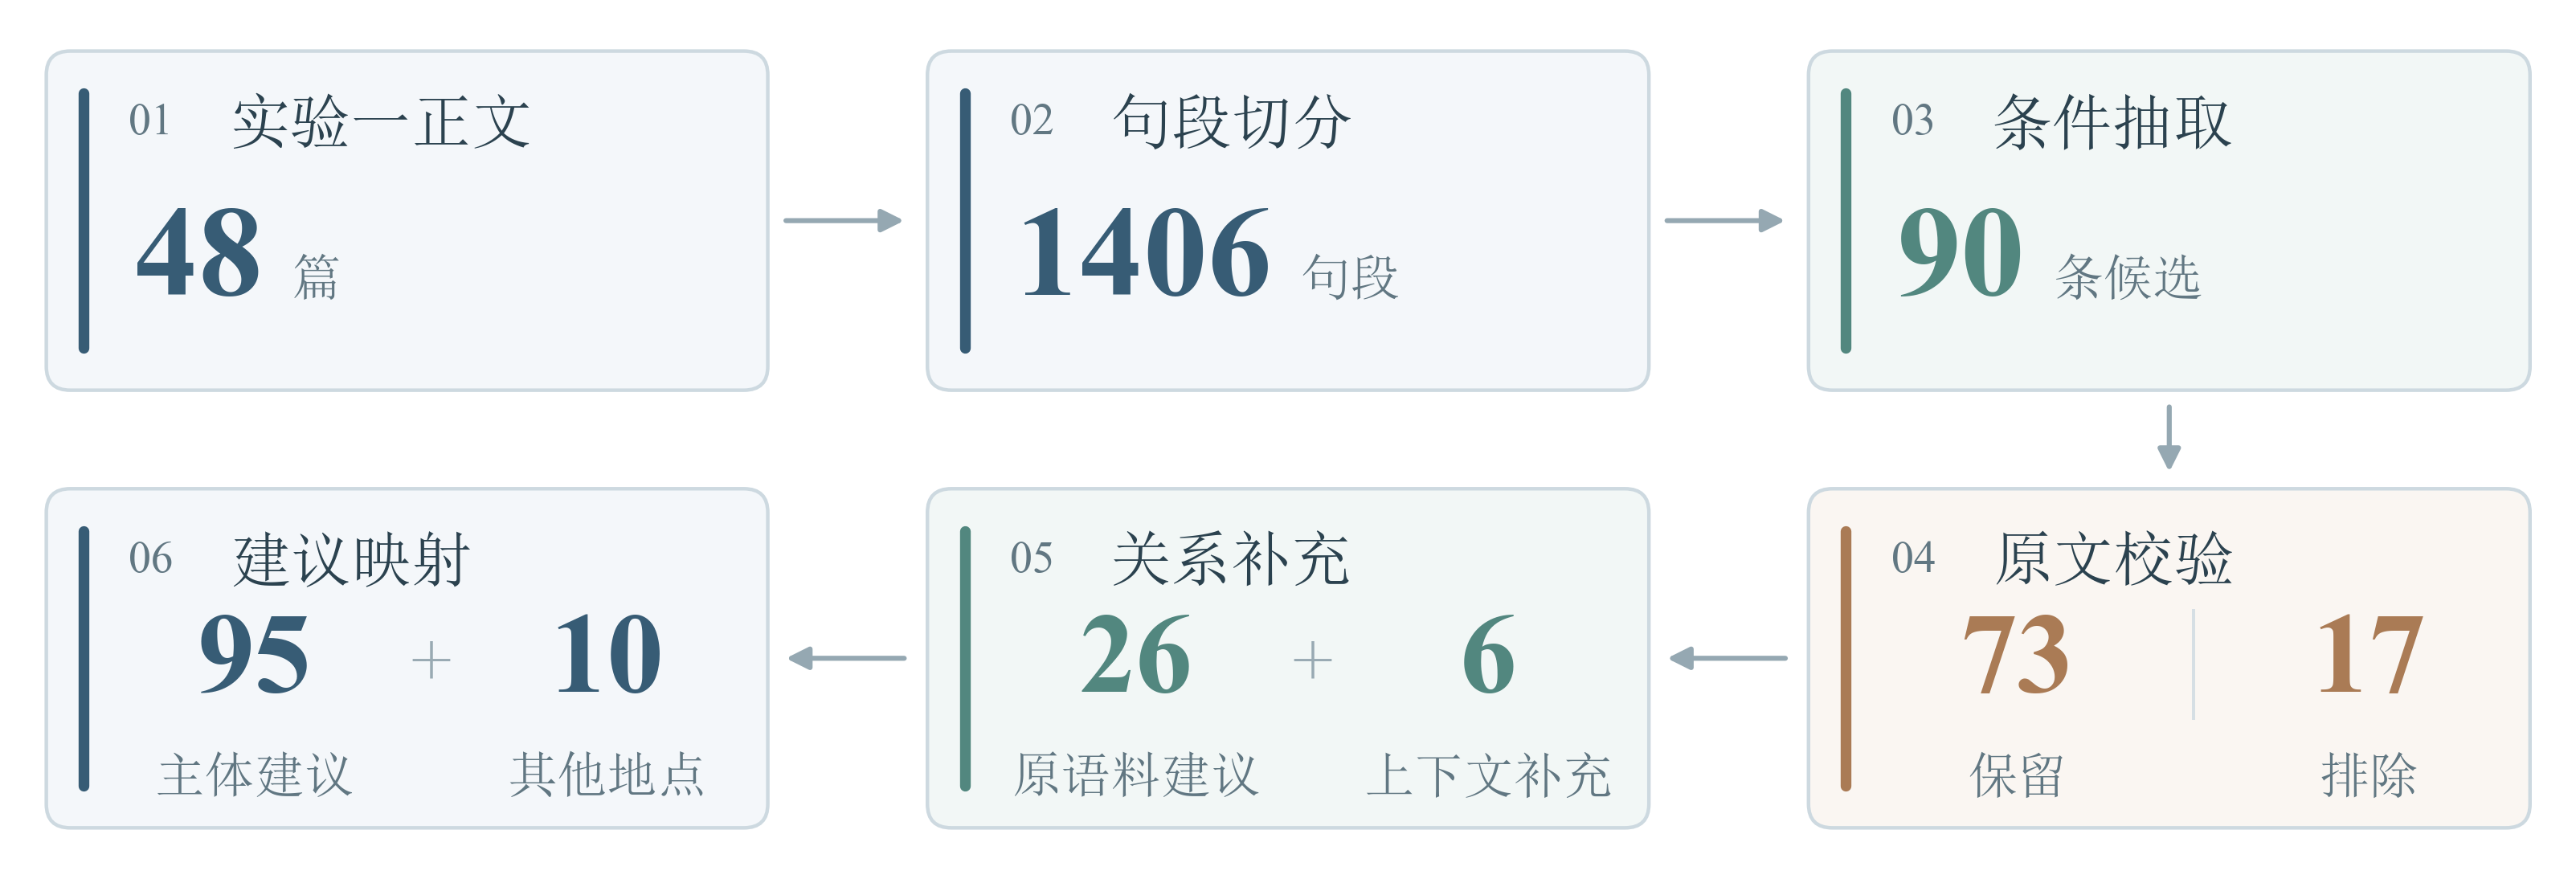

In [4]:
stats=run(BASE)
mapping=json.loads((BASE/"results/条件建议映射表.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{"主体建议":stats["main_after_dedup"],"其他地点":stats["outside_scope"],"建议去重合并":stats["dedup_merges"]}]))
display(pd.DataFrame(mapping)[["mapping_id","condition_text","advice_text","target_scope","provenance_kind"]].head(10))
display(Image(filename=str(BASE/"results/条件建议抽取流程.png")))

## 4 规则对照与边界分析

以21个正例和9个负例比较基础规则与改进规则。样例采用三个景区的同组句式，覆盖天气、人群、必要条件、例外条件和反事实表达，检查条件识别及建议边界。

In [5]:
comparison=evaluate(BASE)
display(pd.DataFrame([{ "方法":name, **{k:v for k,v in values.items() if k!="cases"}} for name,values in comparison["methods"].items()]))
checks=json.loads((BASE/"data/人工校验.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{ "候选编号":key,"处理":row["action"],"依据":row["reason"]} for key,row in checks["candidate_adjustments"].items()]).head(8))

,方法,positive_relation_hits,exact_pair_matches,negative_false_positives
0,基础规则,15,15,3
1,改进规则,18,18,0


,候选编号,处理,依据
0,e5340eabd70bc1c1,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。
1,e5aed47e98f1bc42,exclude,描述回音壁的声学效果，没有提出游客行动建议。
2,1f50937394dda731,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。
3,29c943b53fb49641,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。
4,583769b863a6836b,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。
5,a1d268fe1931c0c6,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。
6,c114ccdfe7f20764,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。
7,e9b8db965872c198,exclude,与补充条目表达同一关系，保留条件、建议及地点较完整的一条。


## 5 分类统计与可视化

主体按去重后的建议组计数。游客类型允许多标签，条件类型按主类统计；不同来源分开呈现。实际适用地点依据建议内容确定。

,来源性质,建议数
0,dataset_corpus,16
1,editorial_route_guide,27
2,official_route_facts,0
3,synthetic_teaching,52


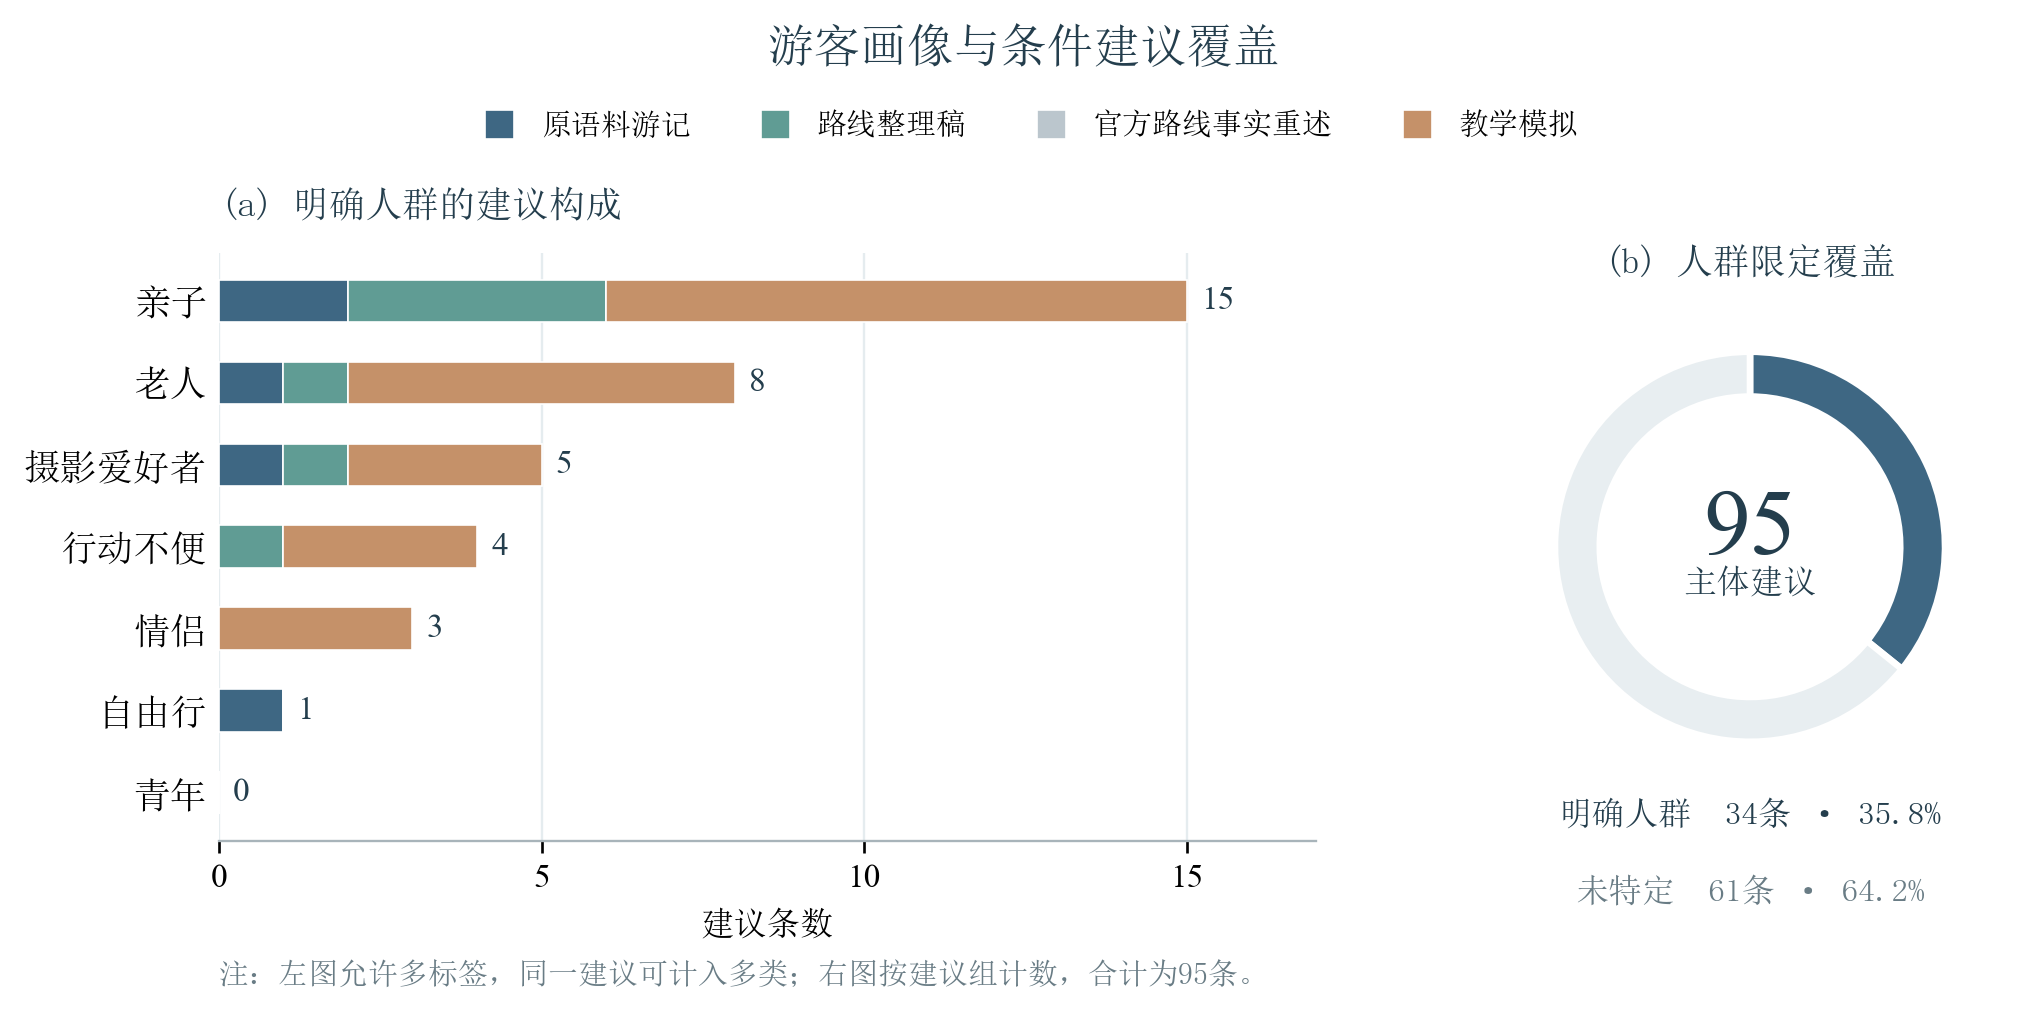

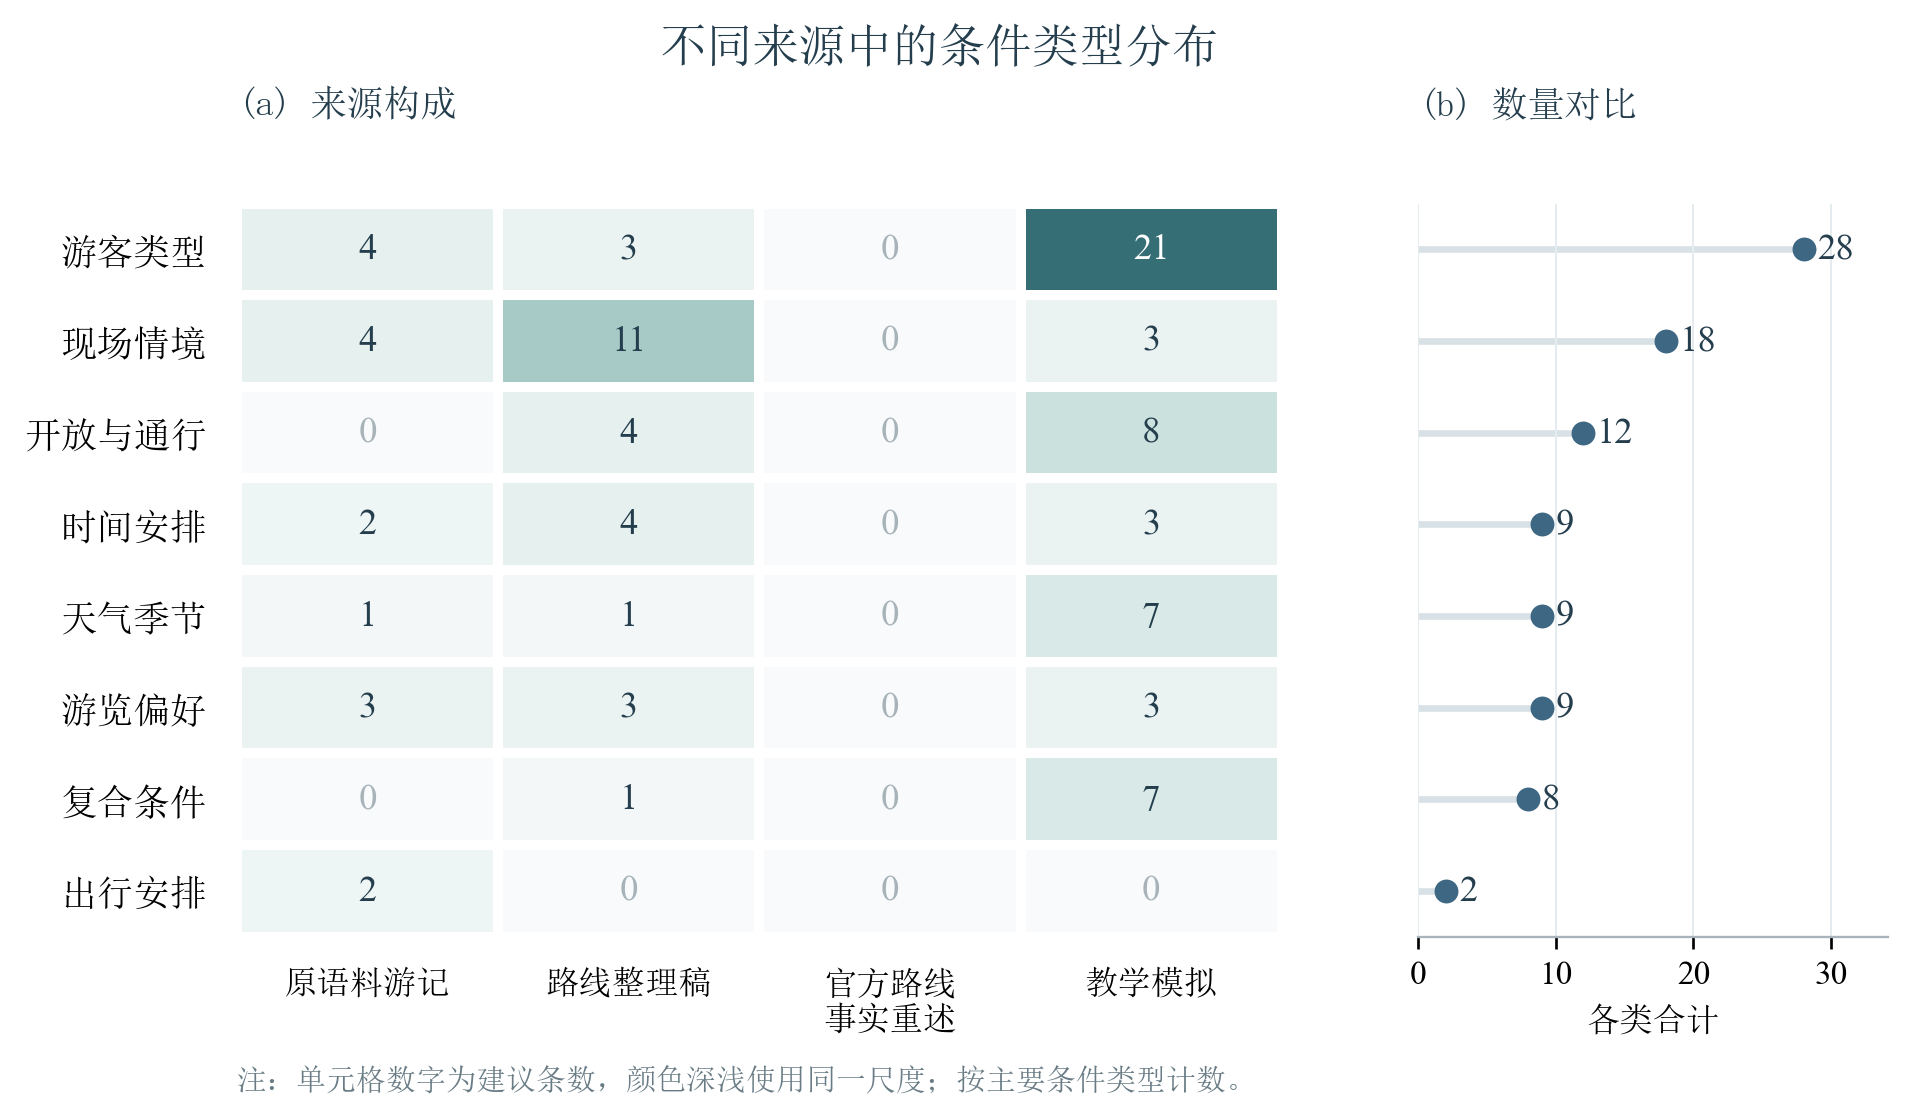

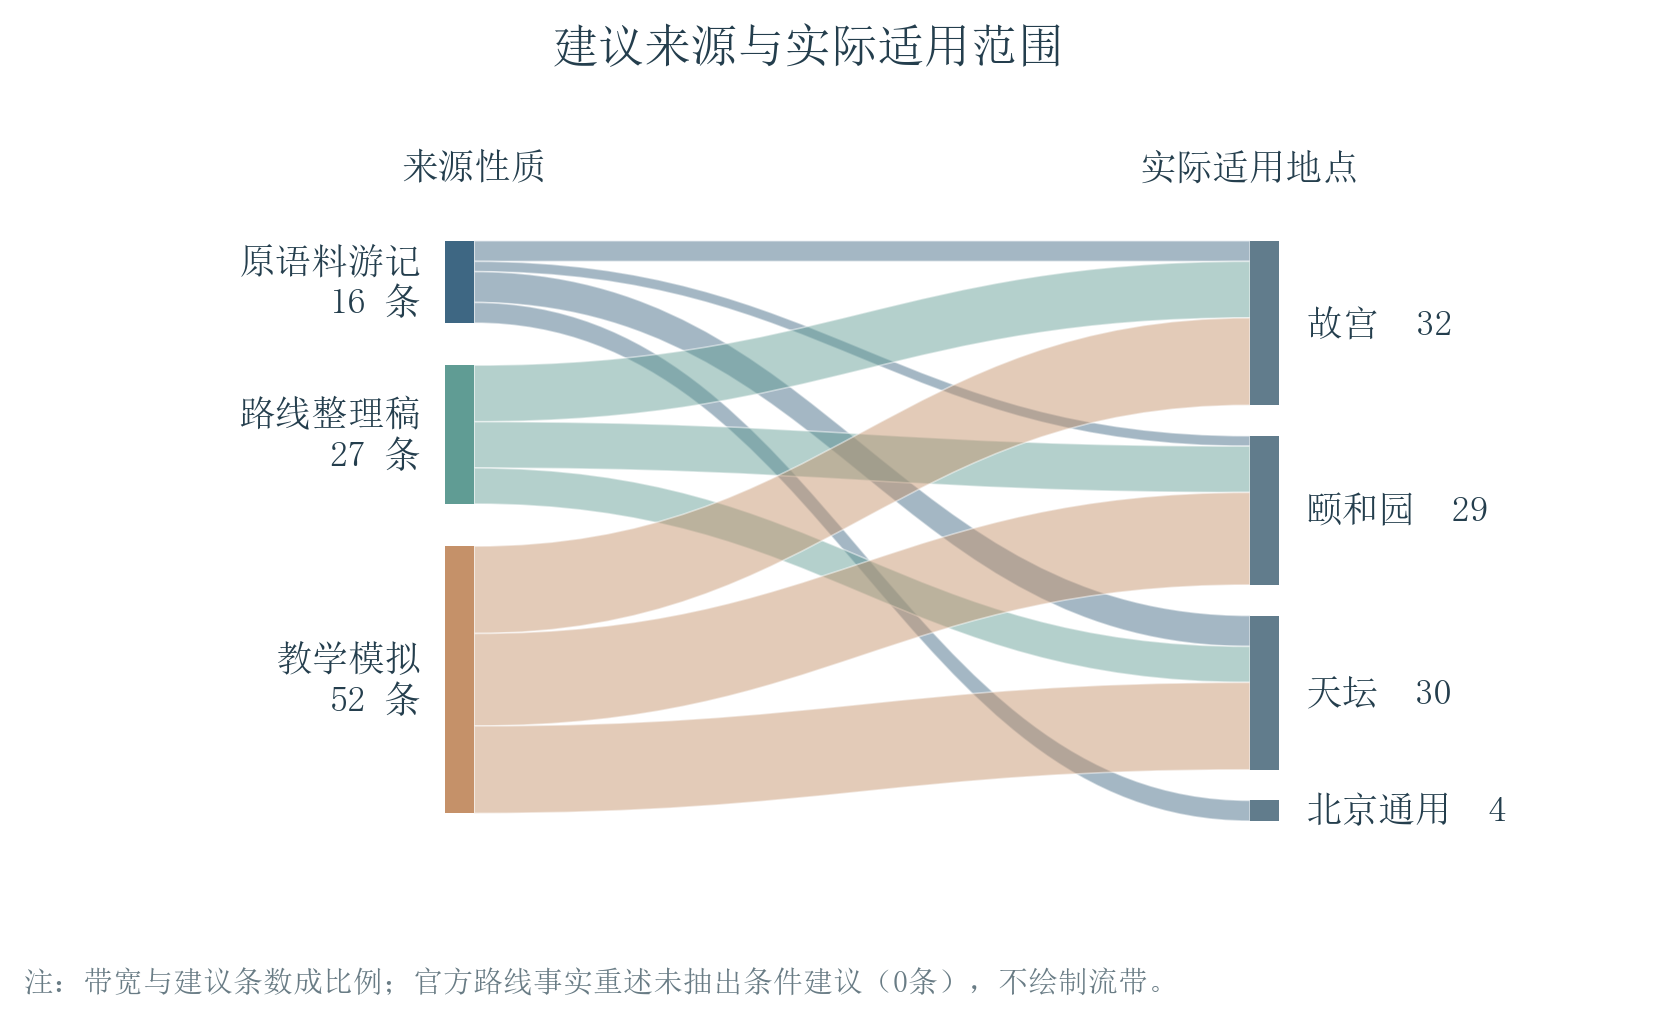

In [6]:
display(pd.DataFrame(stats["by_provenance"].items(),columns=["来源性质","建议数"]))
display(Image(filename=str(BASE/"results/游客类型统计.png")))
display(Image(filename=str(BASE/"results/条件类型统计.png")))
display(Image(filename=str(BASE/"results/来源与适用范围.png")))

## 6 输出与使用

95条主体建议和10条其他地点建议分别保存为JSON；主体另有CSV。results/分句语料.json保存实验一正文及句段位置，results/映射表.html支持按来源筛选并查看原句。后续图谱可按人群、时间和现场情境关联建议，同时保留必要条件与例外条件的区别。

命令行运行：`python run_experiment.py`；结果与关键规则检查：`python verify.py`。